# Day 3: Explain the model, fair price check, save for the app

1. SHAP: which features push price up or down.
2. Fair price check: compare an asking price with the model's price, using a data-driven margin that widens for expensive laptops.
3. Save the fitted model and metadata for the Streamlit app (Day 4).

In [1]:
import json, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import GroupKFold, cross_val_predict
from xgboost import XGBRegressor
import shap

sns.set_theme(style="whitegrid")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
MODELS = ROOT / "models"; MODELS.mkdir(exist_ok=True)

df = pd.read_csv(ROOT / "data" / "clean.csv")
df["Touch_Screen"] = df["Touch_Screen"].astype(int)

y = df["log_price"]
groups = df["model"]
X = df.drop(columns=["price", "log_price", "model"])
cat_cols = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]
num_cols = [c for c in X.columns if c not in cat_cols]
print(X.shape, "| categorical:", len(cat_cols), "| numeric:", len(num_cols))

c:\Users\HP\miniconda3\envs\laptop\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(940, 20) | categorical: 8 | numeric: 12


## 1. Final model

Same XGBoost settings as Day 2, fitted on all 940 rows. The cross-validated predictions (out-of-fold, grouped by model) are kept for calibrating the fair price margin.

In [2]:
def make_pipe():
    pre = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
        ("num", "passthrough", num_cols),
    ])
    xgb = XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=4,
                       subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1)
    return Pipeline([("pre", pre), ("m", xgb)])

pipe = make_pipe()
cv_pred = cross_val_predict(make_pipe(), X, y, cv=GroupKFold(n_splits=5), groups=groups)
pipe.fit(X, y)
print("fitted on", len(X), "rows")

fitted on 940 rows


## 2. SHAP: what drives the price?

SHAP values are in **log-price** units. A value of +0.2 means that feature multiplies the predicted price by about e^0.2 ≈ 1.22 (+22%), relative to the average laptop.

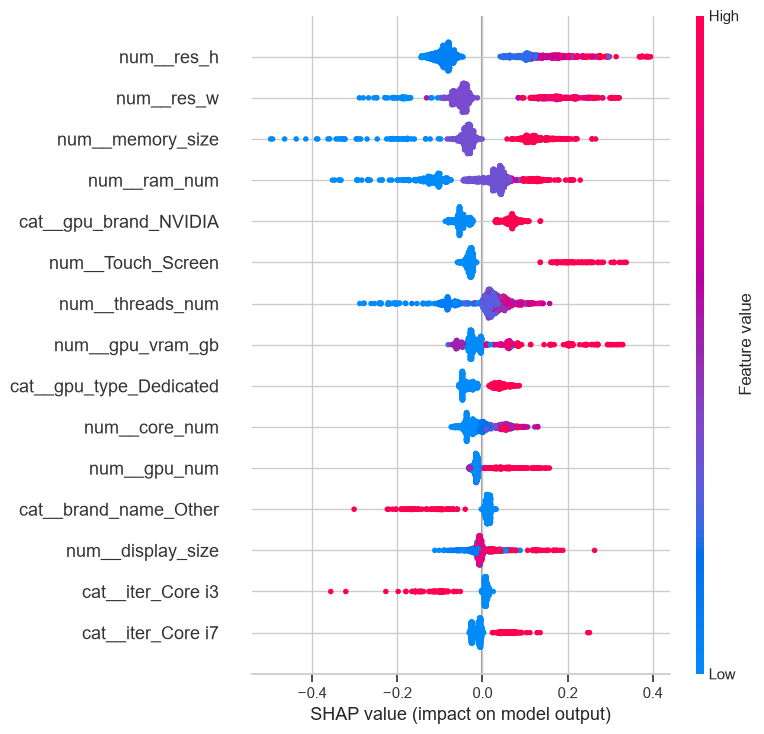

In [3]:
pre, model = pipe.named_steps["pre"], pipe.named_steps["m"]
Xt = pre.transform(X)
Xt = Xt.toarray() if hasattr(Xt, "toarray") else np.asarray(Xt)
names = list(pre.get_feature_names_out())

explainer = shap.TreeExplainer(model)
sv = explainer.shap_values(Xt)

shap.summary_plot(sv, Xt, feature_names=names, max_display=15, show=False)
plt.tight_layout()
plt.savefig(FIG / "shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

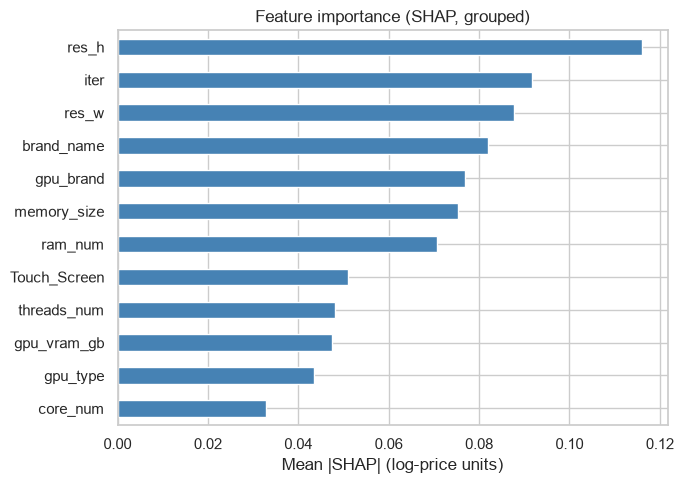

res_h           0.116
iter            0.092
res_w           0.088
brand_name      0.082
gpu_brand       0.077
memory_size     0.075
ram_num         0.071
Touch_Screen    0.051
threads_num     0.048
gpu_vram_gb     0.047
gpu_type        0.043
core_num        0.033
dtype: float32

In [4]:
# Merge one-hot columns back into the original features (sum of mean |SHAP|)
def original_name(n):
    for c in cat_cols:
        if n.startswith(f"cat__{c}_"):
            return c
    return n.replace("num__", "")

imp = (pd.Series(np.abs(sv).mean(axis=0), index=names)
         .groupby(original_name).sum().sort_values(ascending=False))

plt.figure(figsize=(7, 5))
imp.head(12).iloc[::-1].plot.barh(color="steelblue")
plt.xlabel("Mean |SHAP| (log-price units)"); plt.title("Feature importance (SHAP, grouped)")
plt.tight_layout()
plt.savefig(FIG / "shap_importance.png", dpi=150)
plt.show()
imp.round(3).head(12)

## 3. Fair price check

A fixed ₹ margin would be too tight for expensive laptops, as Day 2 showed. Instead, I use the out-of-fold ratio *actual price / predicted price* and take its 10th and 90th percentiles inside four predicted-price tiers. About 80% of real listings fall inside each tier's range.

In [5]:
pred_price = np.exp(cv_pred)
ratio = np.exp(y) / pred_price

tier_edges = np.quantile(pred_price, [0.25, 0.5, 0.75])
tier_id = np.searchsorted(tier_edges, pred_price)

q = pd.DataFrame({"tier": tier_id, "ratio": ratio}).groupby("tier").ratio.quantile([0.1, 0.9]).unstack()
p10, p90 = q[0.1].to_numpy(), q[0.9].to_numpy()

table = pd.DataFrame({
    "tier": ["Q1 cheapest", "Q2", "Q3", "Q4 priciest"],
    "pred_price_from": [pred_price.min(), *tier_edges],
    "ratio_p10": p10, "ratio_p90": p90,
}).round(2)
table

,tier,pred_price_from,ratio_p10,ratio_p90
0,Q1 cheapest,11538.04,0.85,1.19
1,Q2,45853.73,0.88,1.14
2,Q3,65986.98,0.86,1.21
3,Q4 priciest,104153.20,0.79,1.26


In [6]:
def fair_price_check(features, asking_price):
    """features: dict with the same columns as X. Returns the model price, a fair range and a verdict."""
    row = pd.DataFrame([features])[X.columns]
    pred = float(np.exp(pipe.predict(row))[0])
    t = int(np.searchsorted(tier_edges, pred))
    low, high = pred * p10[t], pred * p90[t]
    if asking_price < low:
        verdict = "Looks underpriced"
    elif asking_price > high:
        verdict = "Looks overpriced"
    else:
        verdict = "Fair"
    return {"predicted": round(pred), "fair_low": round(low), "fair_high": round(high), "verdict": verdict}

# Demo on three laptops from the dataset, with asking prices at 70%, 100% and 140% of the listed price
demo = []
for i in [10, 200, 700]:
    f = X.iloc[i].to_dict(); actual = float(df.price.iloc[i])
    for m in [0.7, 1.0, 1.4]:
        r = fair_price_check(f, actual * m)
        demo.append({"brand": df.brand_name.iloc[i], "ram": f["ram_num"], "gpu": df.gpu_family.iloc[i],
                     "asking": round(actual * m), **r})
pd.DataFrame(demo)

,brand,ram,gpu,asking,predicted,fair_low,fair_high,verdict
0,MSI,96,RTX,349999,477958,379707,602447,Looks underpriced
1,MSI,96,RTX,499999,477958,379707,602447,Fair
2,MSI,96,RTX,699999,477958,379707,602447,Looks overpriced
3,HP,16,RTX,88893,129632,102985,163396,Looks underpriced
4,HP,16,RTX,126990,129632,102985,163396,Fair
5,HP,16,RTX,177786,129632,102985,163396,Looks overpriced
6,Lenovo,4,Integrated,14693,20681,17630,24643,Looks underpriced
7,Lenovo,4,Integrated,20990,20681,17630,24643,Fair
8,Lenovo,4,Integrated,29386,20681,17630,24643,Looks overpriced


## 4. Save the model and metadata for the app

In [7]:
joblib.dump(pipe, MODELS / "laptop_price_model.joblib")

meta = {
    "target": "log_price (exp() gives Rs)",
    "feature_order": list(X.columns),
    "categorical": {c: sorted(X[c].astype(str).unique().tolist()) for c in cat_cols},
    "numeric": {c: {"min": float(X[c].min()), "max": float(X[c].max()), "median": float(X[c].median())}
                for c in num_cols},
    "fair_price": {"tier_edges": [float(v) for v in tier_edges],
                   "ratio_p10": [float(v) for v in p10], "ratio_p90": [float(v) for v in p90]},
}
res = ROOT / "reports" / "model_results.csv"
if res.exists():
    meta["cv_results"] = pd.read_csv(res, index_col=0).round(3).to_dict(orient="index")
with open(MODELS / "meta.json", "w") as f:
    json.dump(meta, f, indent=2)

print("saved:", [p.name for p in MODELS.iterdir()])

saved: ['laptop_price_model.joblib', 'meta.json']


## Findings (fill in)

- Top 3-5 features by SHAP, and what the beeswarm shows (e.g. what happens to price when RAM is high vs low).
- How wide is the fair range for cheap vs expensive laptops (see the ratio table)?
- Limits: listing prices from one site and date, no used or refurbished laptops.

Next: Day 4 – Streamlit app, README, deploy.